# AI Security 02360207 - HW1
## Advarserial Attacks on Image Classification Models

<table border="1" cellpadding="6">
<tr>
<th>Name</th>
<th>ID</th>
</tr>
<tr>
<td>Student 1</td>
<td>111111111</td>
</tr>
<tr>
<td>Student 2</td>
<td>111111111</td>
</tr>
<tr>
<td>Student 3</td>
<td>111111111</td>
</tr>
</table>

In this HW we are going to train and attack text classification models on a common image dataset $CFAR10$. 
Complete the notebook cells below. Submit your notebook file after a run. Make sure before submission that you filled the table above and that all the cells have been executed and have desired outputs. If you are a team of two students - no need to fill the details for student 3.
When you submit the file, please name it: hw1_vision_attacks_id1_id2_id3.ipynb (no id3 if you are a pair of students).

**Submission deadline: 2/12/2026**


# AI Usage
The purpose of this HW is to give you hands-on experience with white-box attacks on vision models: to see how the attack parameters change the result, and to understand how and why these attacks work.

With this in mind:
1. You **may** use generative AI tools to help you with this HW.
2. You are responsible for understanding every line of code you submit, and for being able to explain how and why the attack works.

 #### $Ex1.$ Define the following norms over the euclidean space $\mathbb{R}^d$ (double-click the cell to edit text):

* $L_0 = $

* $L_2 = $

* $L_{\infty} = $

#### $Ex2.$ Load the $CFAR10$ dataset and a pre-trained model on it using the code blow. Write an evaluation function, which gets a model and a dataloader, and returns the accuracy, micro and macro F1 scores of the model on the data. You can use sklearn.metrics functions for caluclating the metrics.

In [3]:
import torch
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score, f1_score

Load CFAR10 (already implemented for you):

In [ ]:
transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


Load a pre-traiend model on CFAR10 (already implemented for you):

In [ ]:
# Loads a pretrained ResNet20 trained on CIFAR-10
model = torch.hub.load(
    'chenyaofo/pytorch-cifar-models', 
    'cifar10_resnet20', 
    pretrained=True
)

model.to(device)

#### Visualization helpers (given)
The file `helper.py` (it must be in the same folder as this notebook; **do not modify it**) contains two functions that help you look at your results. Import them once (next cell):

```python
from helper import show_examples, animate_attack
```

---
**1. `show_examples` – original vs. perturbed images**

```python
show_examples(model, x_orig, x_pert, y, n=6, normalized=True, title='')
```

| argument | meaning |
|---|---|
| `model` | the classifier. It must accept images **in the same space** as `x_orig` / `x_pert` (see `normalized`). It is switched to eval mode |
| `x_orig`, `x_pert` | original and perturbed images, tensors of shape `[B, 3, 32, 32]`; `x_pert[i]` is the perturbed version of `x_orig[i]` |
| `y` | the true labels, shape `[B]` |
| `n` | number of examples to show (rows) |
| `normalized` | `True`: the images are in the normalised space of `test_loader` (as the dataloader returns them). `False`: the images are in $[0,1]$ pixel space |
| `title` | optional title of the figure |
| `mean`, `std` | the normalisation constants of `test_loader` – change them only if you changed the normalisation above (default: 0.5, 0.5) |

Each row shows **original | perturbation (amplified, with its $L_0$, $L_2$, $L_\infty$ size) | perturbed image**. The titles contain the true label, the model's prediction and its confidence (green = correct, red = wrong). Examples that the model classified correctly *before* the perturbation are shown first. The function only draws, it returns nothing.

Example – images taken from the dataloader (normalised space):
```python
x, y = next(iter(test_loader))                      # a batch of 128 normalised images
show_examples(model, x, x_perturbed, y, n=4, normalized=True, title='my perturbation')
```
If you work in pixel space (images in $[0,1]$), pass a model that takes such images (e.g. a small wrapper that normalises inside) together with `normalized=False`.

---
**2. `animate_attack` – a GIF of the attack process**

```python
animate_attack(model, x_orig, trajectory, y, normalized=True, path='attack_process.gif', fps=4, title='')
```

| argument | meaning |
|---|---|
| `model` | as above |
| `x_orig` | **one** original image, shape `[3, 32, 32]` |
| `trajectory` | the perturbed image **after every iteration** of your attack: a tensor `[K+1, 3, 32, 32]` (the starting point first, then one entry per iteration) |
| `y` | the true label of this image (an int) |
| `normalized` | as above |
| `path` | where the GIF is saved (it is also displayed in the notebook) |
| `fps` | speed of the animation, in iterations per second |
| `title` | optional title of the figure |
| `mean`, `std` | as above |

The GIF shows, for every iteration: the growing perturbation (amplified, with a fixed gain), the perturbed image with the model's prediction, the class probabilities, and the confidence in the true class. 

**You have to record the trajectory in your own PGD implementation**, for one image:
```python
history = [x + delta]                      # the starting point  (x: ONE image [3,32,32], delta: its perturbation)
for k in range(K):
    ...                                    # your PGD iteration
    history.append(x + delta)              # the perturbed image after every iteration
trajectory = torch.stack(history)          # [K+1, 3, 32, 32]
animate_attack(model, x, trajectory, y_true_of_x, normalized=...)
```
*Tip:* for a nice, slow animation run the attack on that image with a **small budget and tiny steps** (e.g. `eps = 2/255`, `alpha = eps/16`, 30 iterations) and start from `delta = 0`.

(`help(show_examples)` and `help(animate_attack)` print the same documentation.)

In [ ]:
# The visualization helpers live in helper.py, next to this notebook (do not modify it)
from helper import show_examples, animate_attack

Run the model on the dataset and report accuracy, micro and macro F1.

In [ ]:
# your code here

#### $Ex3.$ Run each norm attak ($L_0, L_2, L_{\infty}$) for at least 100 images with *random perturbations*. For each image, sample a random perturbation bounded by the appropriate norm (bounds of your choise, think about the meaning of the bound when choosing $\epsilon$). Complete the functions belowo, run the experiments and report back accuracy of the model on the perturbed dataset for each norm, aggregated over all your perturbed images.

In [ ]:
def perturb_image_L0(image, epsilon):
    """ calculate and add random perturbation to the image with L0 norm bounded by epsilon """
    pass

def perturb_image_L2(image, epsilon):
    """ calculate and add random perturbation to the image with L2 norm bounded by epsilon """
    pass

def perturb_image_L_inf(image, epsilon):
    """ calculate and add random perturbation to the image with L_inf norm bounded by epsilon """
    pass

In [ ]:
# your code here

#### $Ex4$. Below we added a pseudo-code algorithm for the Projected Gradient Descent (PGD) attack. Implement the attack in the cells below and run it on the same samples you tested in the previous part. Report accuracy, micro and macro f1.

 Note that:

* The attack is non-universal - you need to calulatea a unique perturbation for each image.
* Different combinations of hyper-parameters could different results. It is recommended to test multiple options and think of how they impact the attack's optimization process.

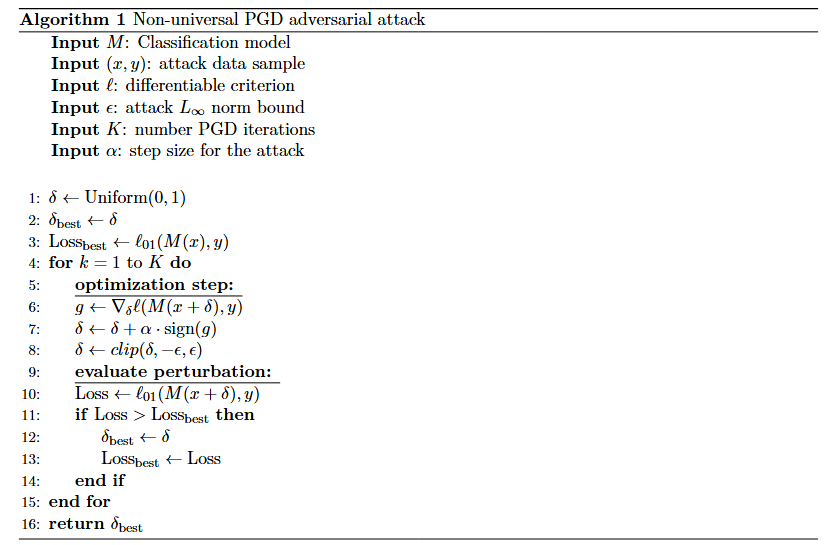

In [ ]:
# your code here